# Imports

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import to_hex
from tqdm import tqdm
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif, SelectKBest
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import RFE
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight


import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

from get_data import get_data

# DATA: radiomics + tabular_data

In [77]:
# Chose wich database use
experiments = ['EGD_IDH', 'EGD_COD', 'PDGM', 'PDGM_TEST_EGD', 'LGG', 'TRAIN_EGD_PDGM']
experiment = experiments[1]
RANDOM_STATE=42
TEST_SIZE=0.15
contrast='flair'
WAVELET=False

train_df, test_df = get_data(experiment, contrast, TEST_SIZE, RANDOM_STATE, wavelet=WAVELET)

########## TRAIN

#### 1p19q
grade_train_label = train_df[train_df['Label']!=-1]['Grade']
class_train_label = train_df[train_df['Label']!=-1]['Class']
y_train_label = train_df[train_df['Label']!=-1]['Label']
x_train_label = train_df[train_df['Label']!=-1].iloc[:, :-4]

#### IDH
grade_train_idh = train_df[train_df['IDH']!=-1]['Grade']
class_train_idh = train_df[train_df['IDH']!=-1]['Class']
y_train_idh = train_df[train_df['IDH']!=-1]['IDH']
x_train_idh = train_df[train_df['IDH']!=-1].iloc[:, :-4]

#### Merged
grade_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Grade']
class_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Class']
y_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Label']
x_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)].iloc[:, :-4]

y_train_merged_idh0 = train_df[(train_df['IDH']==0) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Label']
x_train_merged_idh0 = train_df[(train_df['IDH']==0) & (train_df['Label']!=-1) & (train_df['Grade']<4)].iloc[:, :-4]

########## TEST

#### 1p19q
grade_test_label = test_df[test_df['Label']!=-1]['Grade']
class_test_label = test_df[test_df['Label']!=-1]['Class']
y_test_label = test_df[test_df['Label']!=-1]['Label']
x_test_label = test_df[test_df['Label']!=-1].iloc[:, :-4]

#### IDH
grade_test_idh = test_df[test_df['IDH']!=-1]['Grade']
class_test_idh = test_df[test_df['IDH']!=-1]['Class']
y_test_idh = test_df[test_df['IDH']!=-1]['IDH']
x_test_idh = test_df[test_df['IDH']!=-1].iloc[:, :-4]

#### Merged
grade_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Grade']
class_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Class']
y_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Label']
x_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)].iloc[:, :-4]


##################### DATA STANDARIZATION AND NORMALIZATION
# The standarization and normalization goes before the merge

# Standardize the DataFrame
std_scaler = StandardScaler()

x_train_label_scaled = std_scaler.fit_transform(x_train_label)
x_test_label_scaled = std_scaler.transform(x_test_label)
x_train_idh_scaled = std_scaler.fit_transform(x_train_idh)
x_test_idh_scaled = std_scaler.transform(x_test_idh)
x_train_merged_scaled = std_scaler.fit_transform(x_train_merged)
x_test_merged_scaled = std_scaler.transform(x_test_merged)
#x_train_merged_idh0_scaled = std_scaler.fit_transform(x_train_merged_idh0)

# Initialize the MinMaxScaler
minmax_scaler = MinMaxScaler()

# Normalize the features
x_train_label_normalized = minmax_scaler.fit_transform(x_train_label_scaled)
x_test_label_normalized = minmax_scaler.transform(x_test_label_scaled)
x_train_idh_normalized = minmax_scaler.fit_transform(x_train_idh_scaled)
x_test_idh_normalized = minmax_scaler.transform(x_test_idh_scaled)
x_train_merged_normalized = minmax_scaler.fit_transform(x_train_merged_scaled)
x_test_merged_normalized = minmax_scaler.transform(x_test_merged_scaled)
#x_train_merged_idh0_normalized = minmax_scaler.fit_transform(x_train_merged_idh0_scaled)


# Convert back to DataFrame with original column names
x_train_label = pd.DataFrame(x_train_label_normalized, columns=x_train_label.columns)
x_test_label = pd.DataFrame(x_test_label_normalized, columns=x_test_label.columns)
x_train_idh = pd.DataFrame(x_train_idh_normalized, columns=x_train_idh.columns)
x_test_idh = pd.DataFrame(x_test_idh_normalized, columns=x_test_idh.columns)
x_train_merged = pd.DataFrame(x_train_merged_normalized, columns=x_train_merged.columns)
x_train_merged_idh0 = pd.DataFrame(x_train_merged_idh0_normalized, columns=x_train_merged_idh0.columns)
x_test_merged = pd.DataFrame(x_test_merged_normalized, columns=x_test_merged.columns)

#x_train_label_original, x_train_label_clahe = split_df(x_train_label)
#x_train_idh_original, x_train_idh_clahe = split_df(x_train_idh)
#x_train_merged_original, x_train_merged_clahe = split_df(x_train_merged)

#x_test_label_original, x_test_label_clahe = split_df(x_test_label)
#x_test_idh_original, x_test_idh_clahe = split_df(x_test_idh)
#x_test_merged_original, x_test_merged_clahe = split_df(x_test_merged)

mirrored_x_train_idh = x_train_idh.filter(like='mirrored')
mirrored_x_train_label = x_train_label.filter(like='mirrored')
mirrored_x_train_merged = x_train_merged.filter(like='mirrored')

difference_x_train_idh = x_train_idh.filter(like='difference')
difference_x_train_label = x_train_label.filter(like='difference')
difference_x_train_merged = x_train_merged.filter(like='difference')

border_x_train_idh = x_train_idh.filter(like='border')
border_x_train_label = x_train_label.filter(like='border')
border_x_train_merged = x_train_merged.filter(like='border')

# Define a regular expression pattern to match columns containing 'mirrored' or 'difference'
pattern = 'mirrored|difference|border'

# Use the filter method to select columns matching the pattern
columns_to_drop = x_train_idh.filter(regex=pattern).columns
original_x_train_idh = x_train_idh.drop(columns=columns_to_drop)
columns_to_drop = x_train_label.filter(regex=pattern).columns
original_x_train_label = x_train_label.drop(columns=columns_to_drop)
columns_to_drop = x_train_merged.filter(regex=pattern).columns
original_x_train_merged = x_train_merged.drop(columns=columns_to_drop)


original_x_train_idh = original_x_train_idh.drop(columns=['Age', 'Sex'])
original_x_train_label = original_x_train_label.drop(columns=['Age', 'Sex'])
original_x_train_merged = original_x_train_merged.drop(columns=['Age', 'Sex'])


print(f'full datasets Features: {len(x_train_idh.columns)}')
# {-} = label -> predict 1p19q     {-} = idh -> predict idh        {-} = merged for any (no unkonwn for  any label)
# x_train_{-} train data for predicting {-}
# y_train_{-} labels {-} for training
# x_test_{-} test data for predicting {-}
# y_test_{-} labels {-} for testing
# class_train_{-} tumor name for training data for {-}
# grade_train_{-} tumor grade for training data for {-}

EGD: total 1p19q = 259 | 1p19q+ = 73 | pos rate = 0.282
EGD: total idh = 467 | idh+ =155 | pos rate = 0.332
full datasets Features: 20216


# Methods: pre process and pipe line

In [78]:
def pre_proc(x_train, y_train, x_test, method=None, model=None, features=100, step_size=10, output_file=None, retained_variance=False, verbose=True, pre_proc_model=None):

    if features!='all' and features!='All' and features!='ALL':
        if method == "PCA":
            if verbose:
                print('method: PCA')
            pca = PCA(n_components=features)  # Retain principal components
            pca.fit(x_train)
            x_train_selected = pd.DataFrame(pca.transform(x_train), columns=[f"PC{i+1}" for i in range(features)], index=x_train.index)
            x_test_selected = pd.DataFrame(pca.transform(x_test), columns=[f"PC{i+1}" for i in range(features)], index=x_test.index)

            # Calculate variance retained
            explained_variance = pca.explained_variance_ratio_.sum()
            if verbose:
                print(f"Explained Variance (Retained): {explained_variance:.4f}")

            if output_file is not None:
                # Create a DataFrame with PCA components
                pca_components = pd.DataFrame(pca.components_.T, columns=[f"PC{i+1}" for i in range(features)], index=x_train.columns)
                pca_components.to_csv(output_file, index=True)
                if verbose:
                    print(f"PCA components saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, explained_variance
            else:
                return x_train_selected, x_test_selected

        elif method == 'ANOVA':
            if verbose:
                print('method: ANOVA')
            # Remove constant features
            constant_filter = VarianceThreshold(threshold=0.01)
            x_train_filtered = constant_filter.fit_transform(x_train)
            x_test_filtered = constant_filter.transform(x_test)

            # Perform ANOVA (F-test)
            F_values, p_values = f_classif(x_train_filtered, y_train)

            # Fit SelectKBest on the training set
            selector = SelectKBest(f_classif, k=features)
            x_train_selected_array = selector.fit_transform(x_train_filtered, y_train)
            x_test_selected_array = selector.transform(x_test_filtered)

            selected_columns = x_train.columns[constant_filter.get_support()][selector.get_support()]

            x_train_selected = pd.DataFrame(x_train_selected_array, columns=selected_columns, index=x_train.index)
            x_test_selected = pd.DataFrame(x_test_selected_array, columns=selected_columns, index=x_test.index)

            # Variance calculations
            original_variance = np.var(x_train, axis=0).sum()
            selected_variance = np.var(x_train_selected, axis=0).sum()
            variance_retained = selected_variance / original_variance
            if verbose:
                print(f"Explained Variance (Retained): {variance_retained:.4%}")

            if output_file is not None:
                # Create a DataFrame with feature selection results
                feature_selection = pd.DataFrame({
                    'Feature': selected_columns,
                    'Selected': 1  # All selected columns are marked as 1
                })
                feature_selection.to_csv(output_file, index=False)
                if verbose:
                    print(f"Feature selection results saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, variance_retained
            else:
                return x_train_selected, x_test_selected

        elif method == 'RFE':
            if verbose:
                print('method: RFE')
            # Define the model
            model = XGBClassifier(eval_metric='auc')
            n_features_to_select = min(features, len(x_train.columns))
            if verbose:
                print(f"Number of features: {n_features_to_select}")

            # Start timer
            start_time = time.time()

            if pre_proc_model==None:
                pre_proc_model=model

            # Initialize and fit RFE
            rfe = RFE(estimator=pre_proc_model, n_features_to_select=n_features_to_select, step=step_size)
            rfe.fit(x_train, y_train)

            # Stop timer
            elapsed_time = time.time() - start_time

            x_train_selected = x_train.loc[:, rfe.support_]
            x_test_selected = x_test.loc[:, rfe.support_]

            if verbose:
                print(f"Total time elapsed: {elapsed_time:.2f} seconds")

            # Variance calculations
            original_variance = np.var(x_train, axis=0).sum()
            selected_variance = np.var(x_train_selected, axis=0).sum()
            variance_retained = selected_variance / original_variance
            if verbose:
                print(f"Explained Variance (Retained): {variance_retained:.4%}")

            if output_file is not None:
                # Create a DataFrame with feature selection results
                feature_selection = pd.DataFrame({
                    'Feature': x_train.columns,
                    'Selected': rfe.support_.astype(int)  # 1 for selected, 0 for not selected
                })
                feature_selection.to_csv(output_file, index=False)
                if verbose:
                    print(f"Feature selection results saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, variance_retained
            else:
                return x_train_selected, x_test_selected

        else:
            if verbose:
                print('method: None')
            return x_train, x_test
    else:
        if verbose:
                print('method: None (all features)')
        return x_train, x_test

def selection_anaysis(x_to_analize, y_to_analize, method, model=None, features=50, step_size=10, verbose=True):

    ######### FEATURES EXTRACTION
    x_to_analize, _ =pre_proc(x_to_analize, y_to_analize, x_to_analize, method=method, model=model, features=features, step_size=step_size, verbose=verbose)


    if verbose:
        ########## WAVELET ANALYSIS RELEVANCE
        
        patterns = ["original",
                    "exponential", "gradient", "lbp-2D", "lbp-3D-m1", "lbp-3D-m2", "lbp-3D-k", "logarithm", "square_", "squareroot",
                    "wavelet-LLL", "wavelet-HLL", "wavelet-LHL", "wavelet-LLH", "wavelet-HHL", "wavelet-HLH", "wavelet-LHH", "wavelet-HHH"]
        
        wavelet_patterns = ["wavelet-LLL", "wavelet-HLL", "wavelet-LHL", "wavelet-LLH", "wavelet-HHL", "wavelet-HLH", "wavelet-LHH", "wavelet-HHH"]
    
        column_counts = {pattern: 0 for pattern in patterns}
        total_with_wavelet=0
        in_image=0
        
        new_columns = [col.split('_', 2)[-1] for col in x_to_analize.columns]
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
        
            column_counts[pattern] = sum(col.startswith(pattern) for col in new_columns)
            if pattern in wavelet_patterns:
                total_with_wavelet+=sum(col.startswith(pattern) for col in new_columns)
            in_image+=sum(col.startswith(pattern) for col in new_columns)
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from filter '{pattern}': {count}")
        
        print(f"Wavelet filtered columns: {total_with_wavelet}")
        print(f"original image columns: {len(x_to_analize.columns)-total_with_wavelet}")
        
        print(f"Other columns: {len(new_columns)-in_image}")
    
    
        ########## CLAHE IMPORTANCE ANALYSIS
    
        # Define the substrings to search for
        patterns = ["original", "mirrored"]
        # Initialize a dictionary to store counts
        column_counts = {pattern: 0 for pattern in patterns}
        total_with_wavelet=0
        in_image=0
        
        new_columns = [col.split('_', 1)[-1] for col in x_to_analize.columns]
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
        
            column_counts[pattern] = sum(col.startswith(pattern) for col in new_columns)
            if pattern not in wavelet_patterns:
                total_with_wavelet+=sum(col.startswith(pattern) for col in new_columns)
            in_image+=sum(col.startswith(pattern) for col in new_columns)
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from image '{pattern}': {count}")
    
    
    
        ######### CONTRAST IMPORTANCE ANALYSIS
        patterns = ["T1", "T2", 'FLAIR']
    
        # Initialize a dictionary to store counts
        column_counts = {pattern: 0 for pattern in patterns}
        
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
            column_counts[pattern] = sum(x_to_analize.columns.str.startswith(pattern))
            in_image+=sum(x_to_analize.columns.str.startswith(pattern))
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from contrast '{pattern}': {count}")

    return x_to_analize

In [79]:
def cross_validate_model(model, x_train, y_train, n_splits=5, random_state=42, use_pre_proc=True, method='ANOVA', pre_proc_model=None, features=500, step_size=25):
    """
    Perform stratified k-fold cross-validation and evaluate a model on multiple metrics.

    Parameters:
    - model: Scikit-learn compatible model instance (e.g., LogisticRegression, RandomForestClassifier).
    - x_train: Training feature data (Pandas DataFrame or NumPy array).
    - y_train: Training labels (Pandas Series or NumPy array).
    - n_splits: Number of folds for stratified k-fold cross-validation (default: 5).
    - random_state: Random state for reproducibility (default: 42).
    - pre_proc_fn: Optional preprocessing function, accepts (x_train, y_train, x_val, method) as arguments.

    Returns:
    - results: Dictionary containing mean and standard deviation for AUC, accuracy, recall, and specificity.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    
    cv_results = []  # AUC scores
    metrics_results = []  # Accuracy, Recall, Specificity
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(x_train, y_train), 1):
        print(f'########### Fold: {fold} ###########')
        
        # Split data into training and validation sets
        x_fold_train, x_fold_val = x_train.iloc[train_idx], x_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        # Compute class weights dynamically
        class_weights = compute_class_weight(
            class_weight='balanced',
            classes=np.unique(y_fold_train),
            y=y_fold_train
        )
        model.class_weight = {i: weight for i, weight in enumerate(class_weights)}
        
        # Apply optional preprocessing
        if use_pre_proc:
            x_fold_train, x_fold_val = pre_proc(x_fold_train, y_fold_train, x_fold_val, model=model, method=method, pre_proc_model=pre_proc_model, features=features, step_size=step_size)
        
        # Train the model
        model.fit(x_fold_train, y_fold_train)
        
        # Predict and evaluate
        y_pred = model.predict(x_fold_val)
        y_pred_prob = model.predict_proba(x_fold_val)[:, 1]
        
        # Compute metrics
        acc = accuracy_score(y_fold_val, y_pred)
        rec = recall_score(y_fold_val, y_pred)
        cm = confusion_matrix(y_fold_val, y_pred)
        specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1])  # TN / (TN + FP)
        auc = roc_auc_score(y_fold_val, y_pred_prob)
        
        print(f'AUC: {auc}, Accuracy: {acc}, Recall: {rec}, Specificity: {specificity}')
        cv_results.append(auc)
        metrics_results.append((acc, rec, specificity))
    
    # Summarize results
    results = {
        "Mean AUC": np.mean(cv_results),
        "Std AUC": np.std(cv_results),
        "Mean Accuracy": np.mean([m[0] for m in metrics_results]),
        "Std Accuracy": np.std([m[0] for m in metrics_results]),
        "Mean Recall": np.mean([m[1] for m in metrics_results]),
        "Std Recall":np.std([m[1] for m in metrics_results]),
        "Mean Specificity": np.mean([m[2] for m in metrics_results]),
        "Std Specificity": np.std([m[2] for m in metrics_results])
    }
    
    print('###############################')
    print(f"Mean AUC: {results['Mean AUC']:.4f} ± {results['Std AUC']:.4f}")
    print(f"Mean Accuracy: {results['Mean Accuracy']:.4f} ± {results['Std Accuracy']:.4f}")
    print(f"Mean Recall: {results['Mean Recall']:.4f} ± {results['Std Recall']:.4f}")
    print(f"Mean Specificity: {results['Mean Specificity']:.4f} ± {results['Std Specificity']:.4f}")
    
    return results


# Models testing

In [49]:
from sklearn.svm import LinearSVC

random_state=42

# Define models
models = {
    "SVM RBF": SVC(
        probability=True,  # Needed for AUC calculation
        random_state=random_state
    ),
    "SVM Linear": SVC(
    probability=True,  # Needed for AUC calculation
    random_state=random_state,
    kernel='poly'
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=10000,
        n_jobs=-1,
        random_state=random_state
    ),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),  # Scaling is crucial for KNN
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Naive Bayes": GaussianNB(),
    "Elastic Net": Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=0.5,
        class_weight='balanced',
        max_iter=100000,
        random_state=random_state
    ))
    ]),
    "Logistic Regresor": LogisticRegression(
        penalty='l2',
        solver='liblinear',
        random_state=random_state
    )
}


x_to_pipe = x_train_merged
y_to_pipe = y_train_merged

In [50]:
# Loop through models and perform cross-validation
results_summary_rfe = {}

for model_name, model in models.items():
    pre_proc_model = SVC(
    probability=True,  # Needed for AUC calculation
    random_state=random_state,
    kernel='poly'
    )
    
    print(f"########### Evaluating {model_name} ###########")
    results = cross_validate_model(
        model=model,
        x_train=x_to_pipe,
        y_train=y_to_pipe,
        n_splits=10,
        random_state=random_state,
        use_pre_proc=True,
        pre_proc_model=pre_proc_model,
        features=100,
        step_size=25
    )
    results_summary_rfe[model_name] = results

# Display results
print("\n########### Summary ###########")
for model_name, metrics in results_summary_rfe.items():
    print(f"{model_name}:")
    for metric, value in metrics.items():
        print(f"  {metric}: {value:.4f}")
    print()

########### Evaluating SVM RBF ###########
########### Fold: 1 ###########
method: ANOVA
Explained Variance (Retained): 0.5058%
AUC: 0.9375, Accuracy: 0.7142857142857143, Recall: 0.8333333333333334, Specificity: 0.625
########### Fold: 2 ###########
method: ANOVA
Explained Variance (Retained): 0.5842%
AUC: 0.9183673469387755, Accuracy: 0.7857142857142857, Recall: 0.8571428571428571, Specificity: 0.7142857142857143
########### Fold: 3 ###########
method: ANOVA
Explained Variance (Retained): 0.5177%
AUC: 0.8775510204081632, Accuracy: 0.7857142857142857, Recall: 0.8571428571428571, Specificity: 0.7142857142857143
########### Fold: 4 ###########
method: ANOVA
Explained Variance (Retained): 0.7484%
AUC: 0.7857142857142857, Accuracy: 0.6153846153846154, Recall: 0.6666666666666666, Specificity: 0.5714285714285714
########### Fold: 5 ###########
method: ANOVA
Explained Variance (Retained): 0.5593%
AUC: 0.9047619047619048, Accuracy: 0.7692307692307693, Recall: 1.0, Specificity: 0.57142857142857

In [118]:
###### import torch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, roc_auc_score
from torch.optim.lr_scheduler import LambdaLR

# Define the neural network model
class RegularizedNN(nn.Module):
    def __init__(self, input_size):
        super(RegularizedNN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(128, 1),
            nn.Sigmoid()  # Binary classification
        )

    def forward(self, x):
        return self.model(x)

# Cross-validation function
def cross_validate_nn(model, x_train, y_train, n_splits=5, random_state=23, use_pre_proc=False, method=None, pre_proc_model=None, features=200, step_size=25):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True)
    cv_results = []  # Store AUC scores
    metrics_results = []  # Store accuracy, recall, specificity

    for fold, (train_idx, val_idx) in reversed(list(enumerate(skf.split(x_train, y_train), 1))):
        print(f"########### Fold: {fold} ###########")
        
        # Split data into training and validation sets
        x_fold_train, x_fold_val = x_train.iloc[train_idx], x_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        # Preprocess data if specified
        if use_pre_proc:
            x_fold_train, x_fold_val = pre_proc(x_fold_train, y_fold_train, x_fold_val, model=model, 
                                                method=method, pre_proc_model=pre_proc_model, features=features, step_size=step_size)
        
        
        # Convert data to PyTorch tensors
        x_train_tensor = torch.tensor(x_fold_train.values, dtype=torch.float32)
        y_train_tensor = torch.tensor(y_fold_train.values, dtype=torch.float32).unsqueeze(1)
        x_val_tensor = torch.tensor(x_fold_val.values, dtype=torch.float32)
        y_val_tensor = torch.tensor(y_fold_val.values, dtype=torch.float32).unsqueeze(1)

        train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
        val_dataset = TensorDataset(x_val_tensor, y_val_tensor)

        train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=8)

        # Initialize the neural network model
        input_size = x_fold_train.shape[1]
        nn_model = RegularizedNN(input_size)
        criterion = nn.BCELoss()  # Binary cross-entropy loss
        optimizer = optim.Adam(nn_model.parameters(), lr=0.001, weight_decay=0.01)  # L2 regularization


        # Train the neural network
        num_epochs = 1000
        log_interval = 100  # Log metrics every 10 epochs
        
        # Define the Lambda function for the scheduler
        def lr_lambda(epoch):
            return 1 - (epoch / num_epochs)  # Linearly decay from 1 to 0 over 1000 epochs
        
        # Initialize the scheduler
        scheduler = LambdaLR(optimizer, lr_lambda=lr_lambda)
        
        for epoch in range(num_epochs):
            nn_model.train()
            train_loss = 0
            for x_batch, y_batch in train_loader:
                optimizer.zero_grad()
                outputs = nn_model(x_batch)
                loss = criterion(outputs, y_batch)
                loss.backward()
                optimizer.step()
                train_loss += loss.item()
            scheduler.step()
        
            # Log metrics at intervals
            if (epoch + 1) % log_interval == 0:
                # Evaluate on training data
                nn_model.eval()
                train_preds, train_targets = [], []
                with torch.no_grad():
                    for x_batch, y_batch in train_loader:
                        outputs = nn_model(x_batch).squeeze()
                
                        # Ensure outputs are iterable
                        if outputs.ndimension() == 0:  # If scalar, make it a list
                            outputs = outputs.unsqueeze(0)
                        train_preds.extend(outputs.tolist())
                
                        # Ensure y_batch is iterable
                        if y_batch.ndimension() == 0:  # If scalar, make it a list
                            y_batch = y_batch.unsqueeze(0)
                        train_targets.extend(y_batch.view(-1).tolist())  # Use .view(-1) to ensure 1D tensor
        
                train_preds = torch.tensor(train_preds).numpy()
                train_preds_binary = (train_preds > 0.5).astype(int)
        
                train_acc = accuracy_score(train_targets, train_preds_binary)
                train_auc = roc_auc_score(train_targets, train_preds)
                
                # Evaluate on validation data
                val_preds, val_targets = [], []
                with torch.no_grad():
                    for x_batch, y_batch in val_loader:
                        outputs = nn_model(x_batch).squeeze()
                
                        # Ensure outputs are iterable
                        if outputs.ndimension() == 0:  # If scalar, make it a list
                            outputs = outputs.unsqueeze(0)
                
                        val_preds.extend(outputs.tolist())
                        if y_batch.ndimension() == 0:  # If scalar, make it iterable
                            y_batch = y_batch.unsqueeze(0)
                        val_targets.extend(y_batch.view(-1).tolist())
                        
                val_preds = torch.tensor(val_preds).numpy()
                val_preds_binary = (val_preds > 0.5).astype(int)
        
                val_acc = accuracy_score(val_targets, val_preds_binary)
                val_auc = roc_auc_score(val_targets, val_preds)
        
                print(f"Epoch {epoch + 1}/{num_epochs} - Train Loss: {train_loss:.4f} "
                      f"Train AUC: {train_auc:.4f}, Train Accuracy: {train_acc:.4f} | "
                      f"Val AUC: {val_auc:.4f}, Val Accuracy: {val_acc:.4f}")



        # Evaluate on validation data
        nn_model.eval()
        y_pred_prob = []  # Ensure this is initialized
        y_true = []
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                outputs = nn_model(x_batch).squeeze()
                if outputs.ndimension() == 0:  # If scalar, make it iterable
                    outputs = outputs.unsqueeze(0)
                y_pred_prob.extend(outputs.tolist())
                if y_batch.ndimension() == 0:  # If scalar, make it iterable
                    y_batch = y_batch.unsqueeze(0)
                y_true.extend(y_batch.view(-1).tolist())
        
        # Convert to NumPy arrays
        y_pred_prob = np.array(y_pred_prob)  # Convert list to NumPy array
        y_pred = (y_pred_prob > 0.5).astype(int)


        # Compute metrics
        acc = accuracy_score(y_true, y_pred)
        rec = recall_score(y_true, y_pred)
        cm = confusion_matrix(y_true, y_pred)
        specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1])  # TN / (TN + FP)
        auc = roc_auc_score(y_true, y_pred_prob)
        
        print(f"AUC: {auc}, Accuracy: {acc}, Recall: {rec}, Specificity: {specificity}")
        cv_results.append(auc)
        metrics_results.append((acc, rec, specificity))
    
    # Summarize results
    results = {
        "Mean AUC": np.mean(cv_results),
        "Std AUC": np.std(cv_results),
        "Mean Accuracy": np.mean([m[0] for m in metrics_results]),
        "Std Accuracy": np.std([m[0] for m in metrics_results]),
        "Mean Recall": np.mean([m[1] for m in metrics_results]),
        "Std Recall":np.std([m[1] for m in metrics_results]),
        "Mean Specificity": np.mean([m[2] for m in metrics_results]),
        "Std Specificity": np.std([m[2] for m in metrics_results])
    }
    
    print('###############################')
    print(f"Mean AUC: {results['Mean AUC']:.4f} ± {results['Std AUC']:.4f}")
    print(f"Mean Accuracy: {results['Mean Accuracy']:.4f} ± {results['Std Accuracy']:.4f}")
    print(f"Mean Recall: {results['Mean Recall']:.4f} ± {results['Std Recall']:.4f}")
    print(f"Mean Specificity: {results['Mean Specificity']:.4f} ± {results['Std Specificity']:.4f}")

    return results




pre_proc_model = SVC(
    probability=True,  # Needed for AUC calculation
    random_state=random_state,
    kernel='poly'
    )
    
# Run cross-validation with the neural network
print(f"########### Evaluating {'neural network'} ###########")
results = cross_validate_nn(
    model=None,  # No external model needed; the NN is initialized internally
    x_train=x_to_pipe,
    y_train=y_to_pipe,
    n_splits=10,
    random_state=random_state,
    use_pre_proc=True,
    method='ANOVA',
    pre_proc_model=pre_proc_model,
    features=100,
    step_size=25
)



########### Evaluating neural network ###########
########### Fold: 10 ###########
method: ANOVA
Explained Variance (Retained): 0.5604%
Epoch 100/1000 - Train Loss: 3.8296 Train AUC: 0.9788, Train Accuracy: 0.9417 | Val AUC: 0.9048, Val Accuracy: 0.7692
Epoch 200/1000 - Train Loss: 2.7828 Train AUC: 0.9930, Train Accuracy: 0.9583 | Val AUC: 0.9286, Val Accuracy: 0.7692
Epoch 300/1000 - Train Loss: 2.3518 Train AUC: 0.9983, Train Accuracy: 0.9750 | Val AUC: 0.9048, Val Accuracy: 0.6923


KeyboardInterrupt: 

In [122]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
from sklearn.metrics import precision_recall_curve, accuracy_score, recall_score, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt

# Define the neural network model
class RegularizedNN(nn.Module):
    def __init__(self, input_size):
        super(RegularizedNN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(32, 1),
            nn.Sigmoid()  # Binary classification
        )

    def forward(self, x):
        return self.model(x)


def train_nn_full_data(x_train, y_train, x_test, y_test, pre_proc_model=None, features=100, step_size=25, method='RFE'):
    # Assuming pre_proc is a defined function
    x_train, x_test = pre_proc(x_train, y_train, x_test, 
                               method=method, pre_proc_model=pre_proc_model, features=features, step_size=step_size)
    
    # Convert training data to PyTorch tensors
    x_train_tensor = torch.tensor(x_train.values, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)

    # Create a DataLoader for the training set
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

    # Initialize the neural network model
    input_size = x_train.shape[1]
    model = RegularizedNN(input_size)
    criterion = nn.BCELoss()  # Binary cross-entropy loss
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)  # L2 regularization

    # Training parameters
    num_epochs = 1000
    log_interval = 100  # Log metrics every 100 epochs

    # Define the Lambda function for the scheduler
    def lr_lambda(epoch):
        return 1 - (epoch / num_epochs)  # Linearly decay from 1 to 0 over 1000 epochs

    # Initialize the scheduler
    scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

    # Train the model
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(x_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        
        # Step the scheduler
        scheduler.step()

        # Log metrics at intervals
        if (epoch + 1) % log_interval == 0:
            print(f"Epoch {epoch + 1}/{num_epochs} - Train Loss: {train_loss:.4f}")

    print("Training complete.")

    # Compute precision-recall curve on training set
    model.eval()
    with torch.no_grad():
        y_pred_proba = model(x_train_tensor).squeeze().detach().numpy()

    precision, recall, thresholds = precision_recall_curve(y_train_tensor.numpy(), y_pred_proba)

    # Plot Precision-Recall vs Threshold
    plt.plot(thresholds, precision[:-1], label="Precision")
    plt.plot(thresholds, recall[:-1], label="Recall")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.legend()
    plt.title("Precision-Recall vs Threshold")
    plt.show()

    test_results = test_nn(model, x_test, y_test)

    return model, test_results


def test_nn(model, x_test, y_test):
    # Convert test data to PyTorch tensors
    x_test_tensor = torch.tensor(x_test.values, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

    # Create a DataLoader for the test set
    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # Evaluate the model on the test set
    model.eval()
    y_pred_prob = []
    y_true = []
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            outputs = model(x_batch).squeeze()
            y_pred_prob.extend(outputs.tolist())
            y_true.extend(y_batch.squeeze().tolist())

    # Convert predictions to NumPy arrays
    y_pred_prob = np.array(y_pred_prob)
    y_true = np.array(y_true)

    # Apply thresholding to get binary predictions
    y_pred = (y_pred_prob > 0.5).astype(int)

    # Compute precision-recall curve
    precision, recall, thresholds = precision_recall_curve(y_true, y_pred_prob)

    # Plot Precision-Recall vs Threshold
    plt.plot(thresholds, precision[:-1], label="Precision")
    plt.plot(thresholds, recall[:-1], label="Recall")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.legend()
    plt.title("Precision-Recall vs Threshold")
    plt.show()

    # Compute metrics
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    print(cm)
    specificity = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if cm[0, 0] + cm[0, 1] > 0 else 0  # TN / (TN + FP)
    auc = roc_auc_score(y_true, y_pred_prob)

    print("Test Results:")
    print(f"Accuracy: {acc:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"Specificity: {specificity:.4f}")

    for i in range(len(y_true)):
        print(y_true[i], y_pred_prob[i])

    return {
        "Accuracy": acc,
        "AUC": auc,
        "Recall": rec,
        "Specificity": specificity
    }


method: ANOVA
Explained Variance (Retained): 1.8565%
Epoch 100/1000 - Train Loss: 1.8893
Epoch 200/1000 - Train Loss: 1.8149
Epoch 300/1000 - Train Loss: 0.9874
Epoch 400/1000 - Train Loss: 1.1181
Epoch 500/1000 - Train Loss: 0.8545
Epoch 600/1000 - Train Loss: 0.6707
Epoch 700/1000 - Train Loss: 0.6846
Epoch 800/1000 - Train Loss: 0.6321
Epoch 900/1000 - Train Loss: 0.4654
Epoch 1000/1000 - Train Loss: 0.5997
Training complete.


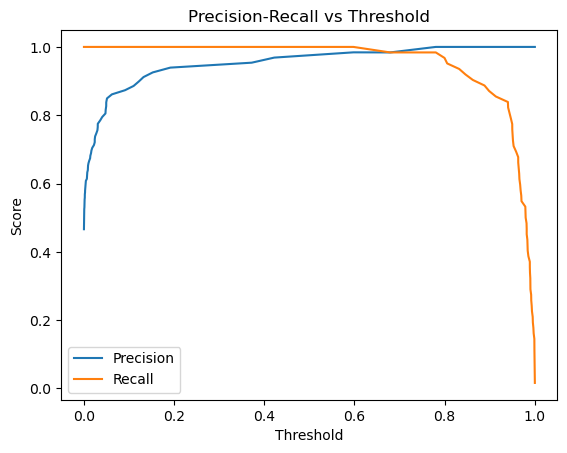

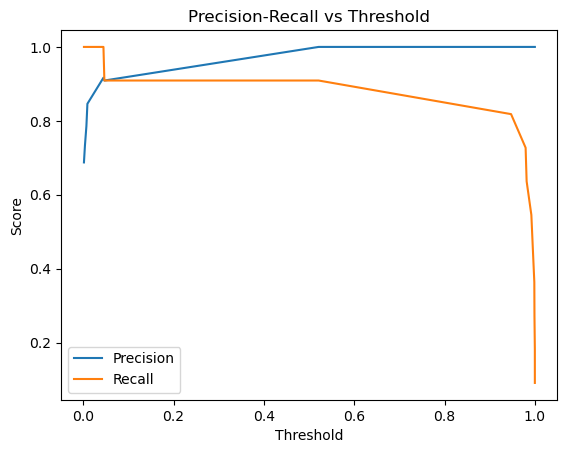

[[ 5  0]
 [ 1 10]]
Test Results:
Accuracy: 0.9375
AUC: 0.9818
Recall: 0.9091
Specificity: 1.0000
0.0 0.0014577341498807073
1.0 0.5210404396057129
0.0 0.009107477031648159
1.0 0.998955488204956
1.0 0.9986360669136047
1.0 0.9920640587806702
0.0 0.0036658989265561104
1.0 0.995329737663269
1.0 0.9998216032981873
0.0 0.00689633609727025
1.0 0.9793514013290405
1.0 0.044630102813243866
0.0 0.04668932408094406
1.0 0.947131872177124
1.0 0.9997953772544861
1.0 0.981613278388977


In [123]:


pre_proc_model = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    random_state=random_state
)

x_train_test_model=x_train_idh
y_train_test_model=y_train_idh
x_test_test_model=x_test_idh
y_test_test_model=y_test_idh
x_train_test_model=x_train_merged
y_train_test_model=y_train_merged
x_test_test_model=x_test_merged
y_test_test_model=y_test_merged

model = train_nn_full_data(x_train_test_model, y_train_test_model, x_test_test_model, y_test_test_model, pre_proc_model=pre_proc_model, features=300, step_size=25, method='ANOVA')


In [ ]:
y_pred

In [121]:
(48+14)/(48+14 +2+5)

0.8985507246376812